In [7]:
import sys
!{sys.executable} -m pip install scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
df = pd.read_csv(r"C:\Users\HP\Downloads\01_iris_flower_classification.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [11]:
df.head()


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [12]:
df.tail()

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica
149,5.9,3.0,5.1,1.8,Iris-virginica


In [13]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 150
Number of columns: 5


In [14]:
print(df.columns)

Index(['sepal_length_cm', 'sepal_width_cm', 'petal_length_cm',
       'petal_width_cm', 'species'],
      dtype='object')


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sepal_length_cm  150 non-null    float64
 1   sepal_width_cm   150 non-null    float64
 2   petal_length_cm  150 non-null    float64
 3   petal_width_cm   150 non-null    float64
 4   species          150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [16]:
df.describe()

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [17]:
print(df.isnull().sum())

sepal_length_cm    0
sepal_width_cm     0
petal_length_cm    0
petal_width_cm     0
species            0
dtype: int64


In [18]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 3


In [19]:
df = df.drop_duplicates()

print("Dataset after removing duplicates:")
print(df.shape)

Dataset after removing duplicates:
(147, 5)


In [20]:
print(df['species'].unique())

['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


In [21]:
print(df['species'].value_counts())

species
Iris-versicolor    50
Iris-virginica     49
Iris-setosa        48
Name: count, dtype: int64


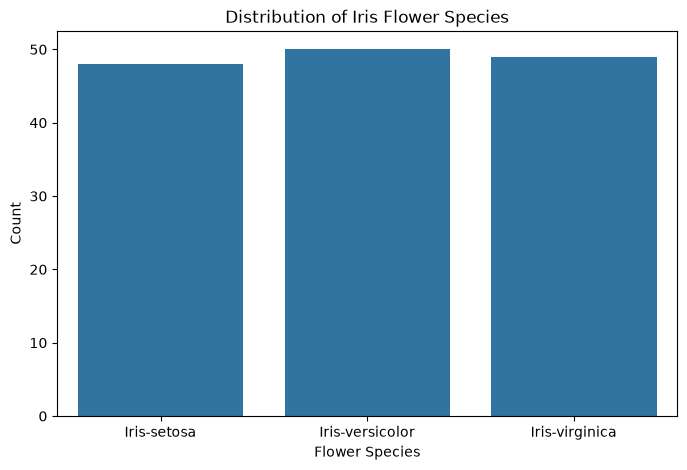

In [22]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='species')

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Count")

plt.show()

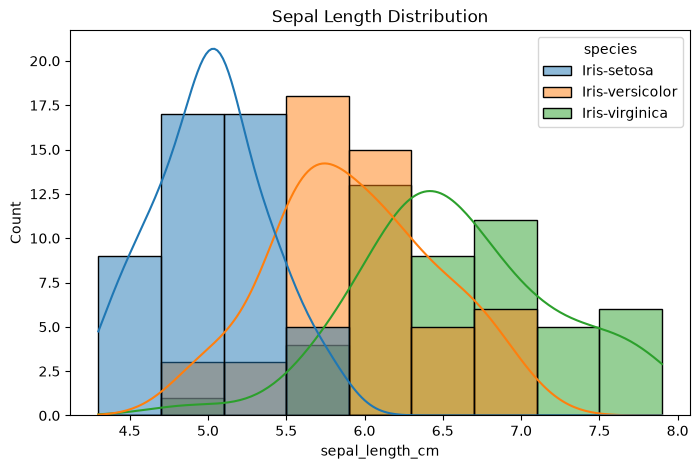

In [23]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='sepal_length_cm',
    hue='species',
    kde=True
)

plt.title("Sepal Length Distribution")
plt.show()

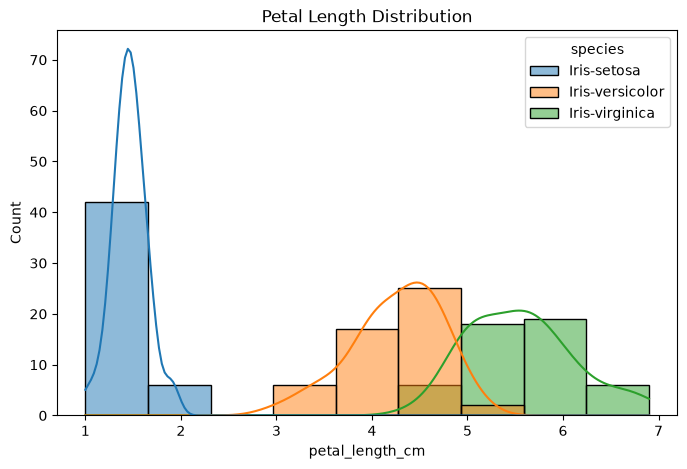

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='petal_length_cm',
    hue='species',
    kde=True
)

plt.title("Petal Length Distribution")
plt.show()

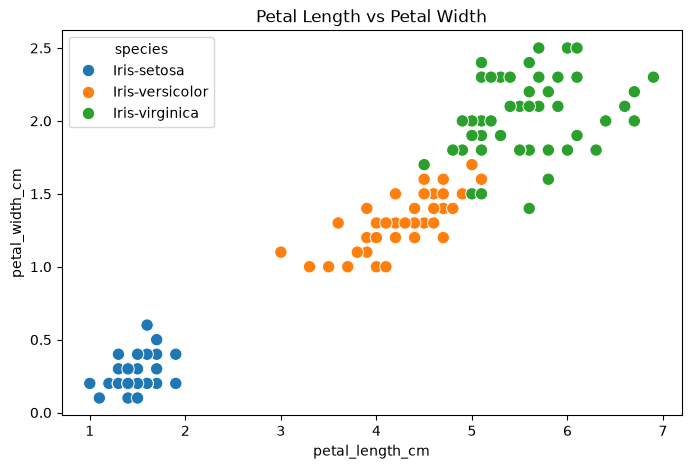

In [25]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='petal_length_cm',
    y='petal_width_cm',
    hue='species',
    s=80
)

plt.title("Petal Length vs Petal Width")
plt.show()

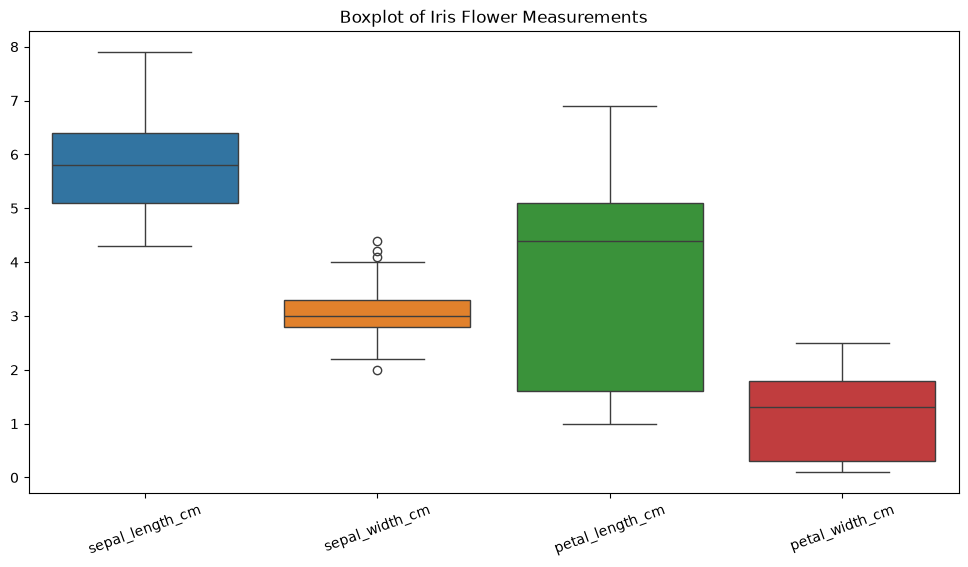

In [26]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df.drop(columns='species'))

plt.title("Boxplot of Iris Flower Measurements")
plt.xticks(rotation=20)
plt.show()

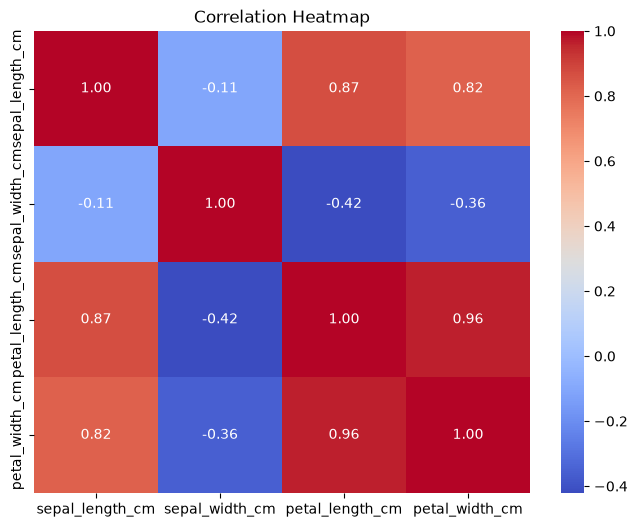

In [27]:
plt.figure(figsize=(8, 6))

correlation = df.drop(columns='species').corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

In [28]:
X = df.drop('species', axis=1)

y = df['species']

print("Input features:")
print(X.head())

print("\nTarget variable:")
print(y.head())

Input features:
   sepal_length_cm  sepal_width_cm  petal_length_cm  petal_width_cm
0              5.1             3.5              1.4             0.2
1              4.9             3.0              1.4             0.2
2              4.7             3.2              1.3             0.2
3              4.6             3.1              1.5             0.2
4              5.0             3.6              1.4             0.2

Target variable:
0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: species, dtype: object


In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (117, 4)
Testing data: (30, 4)


In [30]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [31]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

lr_predictions = lr_model.predict(X_test_scaled)

lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Accuracy:",
      lr_accuracy * 100, "%")

Logistic Regression Accuracy: 93.33333333333333 %


In [32]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

knn_predictions = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, knn_predictions)

print("KNN Accuracy:",
      knn_accuracy * 100, "%")

KNN Accuracy: 93.33333333333333 %


In [33]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:",
      dt_accuracy * 100, "%")

Decision Tree Accuracy: 93.33333333333333 %


In [34]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:",
      rf_accuracy * 100, "%")

Random Forest Accuracy: 96.66666666666667 %


In [35]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'KNN',
        'Decision Tree',
        'Random Forest'
    ],

    'Accuracy': [
        lr_accuracy,
        knn_accuracy,
        dt_accuracy,
        rf_accuracy
    ]
})

results['Accuracy'] = results['Accuracy'] * 100

print(results)

                 Model   Accuracy
0  Logistic Regression  93.333333
1                  KNN  93.333333
2        Decision Tree  93.333333
3        Random Forest  96.666667


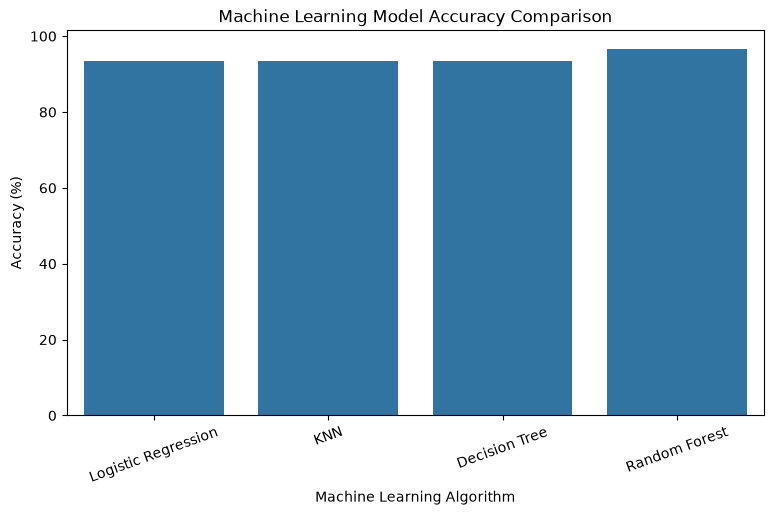

In [36]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x='Model',
    y='Accuracy'
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Algorithm")
plt.xticks(rotation=20)

plt.show()

In [37]:
models = {
    'Logistic Regression': (lr_model, X_test_scaled),
    'KNN': (knn_model, X_test_scaled),
    'Decision Tree': (dt_model, X_test),
    'Random Forest': (rf_model, X_test)
}

best_model_name = results.loc[
    results['Accuracy'].idxmax(), 'Model'
]

best_model, best_X_test = models[best_model_name]

print("Best Performing Model:", best_model_name)
print("Best Accuracy:",
      results['Accuracy'].max(), "%")

Best Performing Model: Random Forest
Best Accuracy: 96.66666666666667 %


In [38]:
best_predictions = best_model.predict(best_X_test)

print(classification_report(
    y_test,
    best_predictions
))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



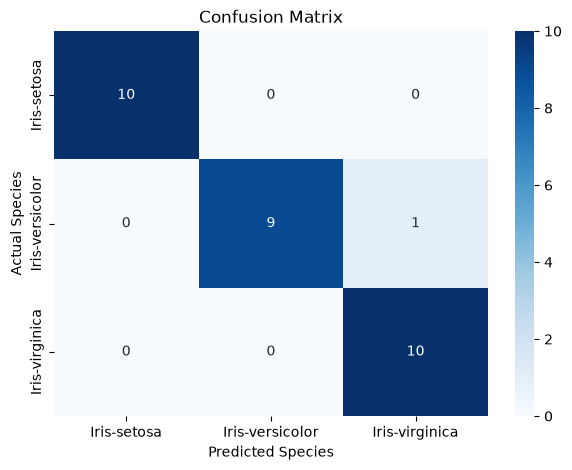

In [39]:
cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.show()

In [40]:
# Enter flower measurements

sepal_length = 5.1
sepal_width = 3.5
petal_length = 1.4
petal_width = 0.2

# Create input dataframe

new_flower = pd.DataFrame(
    [[sepal_length, sepal_width,
      petal_length, petal_width]],

    columns=X.columns
)

# Apply scaling if required

if best_model_name in ['Logistic Regression', 'KNN']:

    new_flower = scaler.transform(new_flower)

# Predict species

prediction = best_model.predict(new_flower)

print("Predicted Iris Flower Species:", prediction[0])

Predicted Iris Flower Species: Iris-setosa


In [ ]:

import os
import pickle

# Get the exact project folder
save_path = r"C:\Users\HP\Downloads\irisflowerclassification"

# Save all three files in that folder
files = {
    "iris_model.pkl": best_model,
    "iris_scaler.pkl": scaler,
    "model_scaled.pkl": best_model_name in [
        "Logistic Regression",
        "KNN"
    ]
}

for filename, obj in files.items():
    full_path = os.path.join(save_path, filename)

    with open(full_path, "wb") as f:
        pickle.dump(obj, f)

    print("Saved:", full_path)

# Verify that files exist
print("\nVerification:")

for filename in files:
    full_path = os.path.join(save_path, filename)
    print(filename, ":", os.path.exists(full_path))

print("\nProject folder:", os.getcwd())


Model saved successfully!
